# Análise ConnectaTel

Como **analista de dados**, seu objetivo é avaliar o **comportamento dos clientes** de uma empresa de telecomunicações na América Latina, a ConnectaTel.

Trabalharemos com informações registradas **até o ano de 2024**, o que permitirá analisar o comportamento do negócio dentro desse período.

Para isso, você trabalhará com três datasets:  

- **plans.csv** → informações dos planos atuais (preço, minutos incluídos, GB incluídos, custo por extra)  
- **users.csv** → informações dos clientes (idade, cidade, data de cadastro, plano, churn)  
- **usage.csv** → detalhe do **uso real** dos serviços (chamadas e mensagens)  

Você deverá **explorar**, **limpar** e **analisar** esses dados para construir um **perfil estatístico** dos clientes, detectar **comportamentos atípicos** e criar **segmentos de clientes**.  

Essa análise permitirá **identificar padrões de consumo**, **desenhar estratégias de retenção** e **sugerir melhorias nos planos** oferecidos pela empresa.

> 💡 Antes de começar, lembre-se de pensar de forma **programática**: quais etapas são necessárias? Em que ordem? O que você quer medir e por quê?


---
## 🧩 Etapa 1: Carregar e explorar

Antes de limpar ou combinar os dados, é necessário **familiarizar-se com a estrutura dos três datasets**.  
Nesta etapa, você validará se os arquivos foram carregados corretamente, conhecerá suas colunas e tipos de dados e detectará possíveis inconsistências.

### 1.1 Carregamento de dados e visualização rápida

**🎯 Objetivo:**  
Ter os **3 datasets prontos na memória**, entender seu conteúdo e realizar uma revisão preliminar.

**Instruções:**  
- Importe as bibliotecas necessárias (por exemplo, `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carregue os arquivos CSV usando `pd.read_csv()`:
  - **`https://practicum-content.s3.us-west-1.amazonaws.com/datasets/plans.csv`**  
  - **`https://practicum-content.s3.us-west-1.amazonaws.com/datasets/users_brasil.csv`**  
  - **`https://practicum-content.s3.us-west-1.amazonaws.com/datasets/usage.csv`**  
- Salve os DataFrames nas variáveis: `plans`, `users`, `usage`.  
- Mostre as primeiras linhas de cada DataFrame usando `.head()`.


In [1]:
# importar bibliotecas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# carregar arquivos
plans = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/plans.csv')
users = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/users_brasil.csv')
usage = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/usage.csv')

In [3]:
# mostrar as primeiras 5 linhas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar as primeiras 5 linhas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Santos,38,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Matheus,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Valentina,Souza,57,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Matheus,Souza,69,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Matheus,Torres,63,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar as primeiras 5 linhas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Dica:** Se você não usar `print()`, a tabela será exibida melhor.

### 1.2 Exploração da estrutura dos datasets

**🎯 Objetivo:**  
Conhecer a **estrutura de cada dataset**, revisar quantas linhas e colunas eles têm, identificar os **tipos de dados** de cada coluna e detectar possíveis **inconsistências ou valores ausentes** antes de iniciar a análise.

**Instruções:**  
- Revise o **número de linhas e colunas** de cada dataset usando `.shape`.  
- Use `.info()` em cada DataFrame para obter um **resumo completo** de colunas, tipos de dados e valores não nulos.  

In [6]:
# revisar o número de linhas e colunas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspeção de plans com .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspeção de users com .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspeção de usage com .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩 Etapa 2: Identificação de problemas de qualidade dos dados

### 2.1 Revisão de valores ausentes

**🎯 Objetivo:**  
Detectar a presença e a magnitude de valores ausentes para avaliar se eles afetam a análise ou exigem imputação/remoção.

**Instruções:**  
- Conte os valores ausentes por coluna para cada dataset.
- Calcule a proporção de valores ausentes por coluna para cada dataset.

O dataset `plans` tem apenas 2 linhas e podemos observar que não possui valores ausentes, por isso não precisa de exploração adicional.

<br>
<details>
<summary>Clique para ver a dica</summary>
Use `.isna().sum()` para contar valores ausentes e `.isna().mean()` para calcular a proporção.


In [10]:
# quantidade de valores ausentes para users
print(users.isna().sum())
print(users.isna().mean() * 100) # proporção em porcentagem (ou use .mean direto para proporção de 0 a 1)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# quantidade de valores ausentes para usage
print(usage.isna().sum())
print(usage.isna().mean() * 100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentário**: Dê dois cliques neste bloco e escreva seu diagnóstico no final. Inclua o que você observa e qual ação recomendaria para cada caso.

💡 **Nota:** Justifique suas decisões brevemente (1 linha por caso).
* Dica:
 - Se uma coluna tiver **mais de 80–90% de valores ausentes**, normalmente ela é **ignorada ou removida**.  
 - Se tiver **entre 5% e 30%**, geralmente é necessário **investigar para imputar ou manter como valores ausentes**.  
 - Se for **menor que 5%**, costuma ser um caso simples de imputação ou manutenção como valores ausentes.

 ---

**Valores ausentes**  
- Quais colunas têm valores ausentes e em qual proporção?
- Indique o que você faria: imputar, remover ou ignorar?
  No Dataset `users` temos duas colunas com valores ausentes, sendo elas: city e churn_date. Em city temos 469 valores em falta, com uma proporção de 11.73%, aqui a ação recomendada seria investigar e manter, visto que essa é uma porcentagem dentro de 5% e 30%. Na coluna crurn_date temos 3.534 valores em falta, com uma proporção de 88.35%, a ação recomendada aqui seria mantes como ausente, visto que é uma porcentagem superior a 80%.
  No Dataset `usage` temos três colunas com valores ausentes, sendo elas: date, duration e length. Em date temos 50 valores em falta, com uma proporção de 0.13%, aqui a ação recomendada seria remover, visto que essa é uma porcentagem inferior a 5%. Na coluna duration temos 22.076 valores em falta, com uma proporção de 55.19%, a ação recomendada aqui seria investigar, pois é uma proporção alta que requer análise prévia. Na coluna length temos 17.896 valores em falta, com uma proporção de 44.74%, a ação recomendada aqui seria investigar, pois é uma proporção alta que requer análise prévia.


### 2.2 Detecção de valores inválidos e sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que não deveriam estar no dataset.

**Instruções:**
- Explore as colunas numéricas com **um resumo estatístico** e descreva brevemente o que encontrou.
- Explore as colunas categóricas **relevantes**, revisando seus valores únicos e descrevendo brevemente o que encontrou.


O dataset `plans` tem apenas 2 linhas, por isso não precisa de exploração adicional.

In [12]:
# explorar colunas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- Na coluna `user_id`, em  relação a coluna aos valores de count, todos os 4000 registros são válidos, confirmando que não existem valores em falta. em relação aos valores min e max, percebemos que os IDs estão compreendidos entre 10000 e 13999. A média e a mediana são exatamente iguais, o que significa que existe uma distribuição uniforme, sem saltos anômalos. 
- Na coluna `age`, o valor min (-999) está como negativo, ou seja, algum dado pode estar corrompido. Temos um desvio padrão distorcido, onde 123 anos de desvio padrão é algo impossível para a idade da humanidade, aqui também pode ter dados corrompidos, aqui seria interessante avaliar se existe algum dado com valor alto, realizar um ajuste e recalcular os dados. E por fim mean, também se encontra distorcido, pois a presença do -999 puxa a média para baixo. Aqui seria interessante avaliar quantos dados possuem esse valor negativo, realizar um ajuste e recalcular os dados.

In [13]:
# explorar colunas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- As colunas `id` e `user_id`, na análise do arquivo de uso (usage) mostrou que a ligação entre as tabelas funciona perfeitamente: todas as 40.000 ações registradas na coluna id (numeradas de 1 a 40.000) pertencem a usuários com códigos entre 10.000 e 13.999 na coluna user_id, exatamente como na tabela de cadastros.
- As colunas `duration` e `length`, possuem muitas informações faltando e alguns dados estranhos, por exemplo: Coluna duration (duração): Tem apenas 17.924 registros preenchidos, o que significa que 55,19% dos dados estão faltando. Quando há dados, o tempo médio é de 5,20 e a maioria das ações (75%) dura até 6,99.   Coluna length (tamanho): Tem 22.104 registros, deixando 44,74% de valores em falta. O valor médio é 52,13 e o valor do meio (mediana) é 50,00. No entanto, existem valores absurdamente altos de até 1.490,00 que fogem bastante do padrão (o chamado desvio padrão é de 56,61). Como ambas as colunas também possuem valores zerados ($0,00$), será necessário limpar e corrigir esses dados antes de fazer análises mais profundas.

In [14]:
# explorar colunas categóricas de users
colunas_user = ['city', 'plan']
for coluna in colunas_user:
    print(f"--- Valores únicos para: {coluna} ---")
    print(users[coluna].value_counts(dropna=False))
    print("\n")

--- Valores únicos para: city ---
Rio de Janeiro    808
Brasília          730
São Paulo         616
NaN               469
Fortaleza         450
Floripa           424
Belém             407
?                  96
Name: city, dtype: int64


--- Valores únicos para: plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64




- A coluna `city` apresenta concentração nas cidades do Rio de Janeiro (808), Brasília (730) e São Paulo (616). Porém, possui 469 valores nulos (NaN) e 96 valores sentinela (?), totalizando 565 registros (14,13%) com localização desconhecida que precisam ser padronizados, por exemplo: substituir por 'Desconhecido'.
- A coluna `plan` está 100% preenchida e sem erros. Mostra que o plano Basico é o mais popular com 2.595 usuários (64,88%), enquanto o Premium conta com 1.405 usuários (35,12%).

In [15]:
# explorar coluna categórica de usage
print(usage['type'].value_counts(dropna=False))

text    22092
call    17908
Name: type, dtype: int64


- A coluna `type` encontra-se completamente preenchida e sem valores nulos, contando com um total de 40.000 interações divididas em duas categorias principais: text, que lidera com 22.092 registos (55,23%), e call, com 17.908 registos (44,77%), demonstrando um uso equilibrado entre mensagens e chamadas pelos utilizadores.   

---
✍️ **Comentário**: Dê dois cliques neste bloco e escreva seu diagnóstico. Inclua o que você observa e qual ação recomendaria para cada caso.

**Valores inválidos ou sentinels**  
- Em quais colunas você encontrou valores inválidos ou sentinels?  
- Qual ação você tomaria?
  *Inclui essa análise nos blocos já preenchidos anteriormente. Contudo, ressalto que alguns casos não precisam de reanálise, mas outros sim. Diante disso, aconselho reorganização dos dados e uma nova atualização dos resultados, visto que erros podem impactar fortemente nos resultados e consequentemente em tomada de decisão.

### 2.3 Revisão e padronização de datas

**🎯 Objetivo:**  
Garantir que as colunas de data estejam formatadas corretamente e detectar anos fora do intervalo esperado que indiquem erros de captura.

**Instruções:**  
- Converta as colunas de data para tipo data e certifique-se de que o código seja robusto a erros.  
- Revise quantas vezes cada ano aparece.
- Identifique datas impossíveis (ex.: anos futuros ou negativos).

Considere que temos dados registrados até o ano de 2024.

In [16]:
# Converter para data a coluna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Converter para data a coluna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar os anos presentes em `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False)


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

Em `reg_date`, ... dê dois cliques neste bloco e escreva o que você observa.

In [19]:
# Revisar os anos presentes em `date` de usage
usage['date'].dt.year.value_counts(dropna=False)


2024.0    39950
NaN          50
Name: date, dtype: int64

Em `date`, ... dê dois cliques neste bloco e escreva o que você observa.  
Basearemos a análise nessas datas.

✍️ **Comentário**: escreva seu diagnóstico e inclua **qual ação você recomendaria** para cada caso:

**Datas fora do intervalo esperado**  
- Aparecem anos impossíveis? (anos muito antigos ou ainda não transcorridos no momento em que os dados foram salvos)
  Sim. Na coluna reg_date aparecem 40 registos associados ao ano de 2026, o que mostra uma inconsistência temporal, uma vez que se consideram dados até 2024. Na coluna date, existem apenas 50 valores nulos (NaN), mas nenhum ano inválido.
- O que você faria com eles?
  Para os registos com o ano 2026 em reg_date, a ação recomendada é investigar a origem e convertê-los em valores nulos (NaN) ou filtrá-los, pois representam datas futuras inválidas, e removê-los. Para os 50 valores NaN na coluna date de usage, a ação recomendada é a remoção dessas linhas, dado que representam uma proporção inferior a 0,13%, causando impacto mínimo na base de dados.

---

## 🧩 Etapa 3: Limpeza básica de dados

### 3.1 Corrigir sentinels e datas impossíveis
**🎯 Objetivo:**  
Aplicar regras de limpeza para substituir valores sentinels e corrigir datas impossíveis.

**Instruções:**  
- Em `age`, substitua o sentinel **-999** pela mediana.
- Em `city`, substitua o sentinel `"?"` por valores ausentes (`pd.NA`).  
- Marque como ausentes (`pd.NA`) as datas fora do intervalo esperado.

In [20]:
# Substituir -999 pela mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)
# Verificar alterações
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Substituir ? por NA em city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar alterações
users['city'].value_counts(dropna=False)


Rio de Janeiro    808
Brasília          730
São Paulo         616
NaN               565
Fortaleza         450
Floripa           424
Belém             407
Name: city, dtype: int64

In [23]:
# 1. Garantir que a coluna está no formato datetime (convertendo erros em NaT)
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# 2. Marcar datas com anos superiores a 2024 como NaT (Not a Time)
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# 3. Verificar as alterações por ano
users['reg_date'].dt.year.value_counts(dropna=False)


2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64

### 3.2 Tratar valores ausentes
**🎯 Objetivo:**  
Decidir o que fazer com os valores ausentes de acordo com sua proporção e relevância.

**Instruções:**
- Verifique se os valores ausentes em `duration` e `length` são **MAR** (Missing At Random), revisando se dependem da coluna `type`.  
  Se confirmar que são MAR, **deixe-os como valores ausentes** e justifique a decisão.

In [24]:
# Verificação MAR em usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean())


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [25]:
# Verificação MAR em usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean())


type
call    0.99933
text    0.00000
Name: length, dtype: float64

Dê dois cliques aqui e escreva seu diagnóstico sobre os valores ausentes em `duration` e `length`.

Os dados são explicitamente MAR (Missing At Random), pois a ausência de valores nas colunas duration e length não ocorre ao acaso, mas depende diretamente da categoria presente na coluna type (as chamadas medem duração, enquanto as mensagens de texto medem comprimento).
Decisão recomendada: Deixá-los como valores ausentes (NaN). Tentar preencher ou imputar estes valores artificialmente corromperia a lógica do negócio, uma vez que uma mensagem de texto não tem "duração de chamada" da mesma forma que uma chamada não tem "comprimento de mensagem de texto".

---

## 🧩 Etapa 4: Summary statistics de uso por usuário


### 4.1 Agrupação por comportamento de uso

🎯**Objetivo**: Resumir as variáveis principais da tabela `usage` **por usuário**, criando métricas que representem seu comportamento real de uso histórico.

**Instruções:**:
1. Construa uma tabela agregada de `usage` por `user_id` que inclua:
- número total de mensagens  
- número total de chamadas  
- total de minutos de chamadas

2. Renomeie as colunas para que tenham nomes claros:  
- `quant_mensagens`  
- `quant_chamadas`  
- `quant_minutos_chamada`
3. Combine essa tabela com `users`.

In [26]:
# Colunas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) # conhecer o total de mensagens
usage["is_call"] = (usage["type"] == "call").astype(int) # conhecer o total de chamadas


# Agrupar informações por usuário
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renomear colunas
usage_agg = usage_agg.rename(columns={
    "is_text": "quant_mensagens",
    "is_call": "quant_chamadas",
    "duration": "quant_minutos_chamada"
})
# observar resultado
usage_agg.head(3)

,user_id,quant_mensagens,quant_chamadas,quant_minutos_chamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Combinar a tabela agregada com o dataset de usuários
user_profile = pd.merge(users, usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,quant_mensagens,quant_chamadas,quant_minutos_chamada
0,10000,Carlos,Santos,38.0,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Matheus,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Valentina,Souza,57.0,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Matheus,Souza,69.0,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Matheus,Torres,63.0,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumo estatístico por usuário durante 2024

🎯 **Objetivo:** Analisar as colunas numéricas e categóricas dos usuários para identificar intervalos, valores extremos e distribuição dos dados antes de continuar com a análise.

**Instruções:**  
1. Para as colunas **numéricas** relevantes, obtenha um resumo estatístico (média, mediana, mínimo, máximo etc.).  
2. Para a coluna **categórica** `plan`, revise a distribuição em **porcentagens** de cada categoria.

In [29]:
# Resumo estatístico das colunas numéricas
user_profile.describe()


,user_id,age,quant_mensagens,quant_chamadas,quant_minutos_chamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [30]:
# Distribuição percentual do tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩 Etapa 5: Visualização de distribuições (uso e clientes) e outliers


### 5.1 Visualização de distribuições

🎯 **Objetivo:**  
Entender visualmente como as variáveis principais de **uso** e de **clientes** se comportam, observar se existem diferenças de acordo com o tipo de plan e analisar a **forma da distribuição**.

**Instruções:**  
Crie **histogramas** para as seguintes colunas:  
- `age` (idade dos usuários)
- `quant_mensagens`
- `quant_chamadas`
- `total_minutos_chamada`

Depois de cada gráfico, escreva um **insight** sobre o plan e a variável, por exemplo:  
- "Dentro do plan Premium, há maior proporção de..."  
- "Os usuários Básico tendem a fazer ... chamadas e enviar ... mensagens." ou "Não existe nenhum padrão."
- Que tipo de distribuição ela tem? (simétrica, assimétrica à direita ou à esquerda)

**Dica**  
Para cada histograma:
- Use `hue='plan'` para ver como as distribuições variam de acordo com o plan (Básico ou Premium).
- Use `palette=['skyblue','green']`
- Adicione título e etiquetas

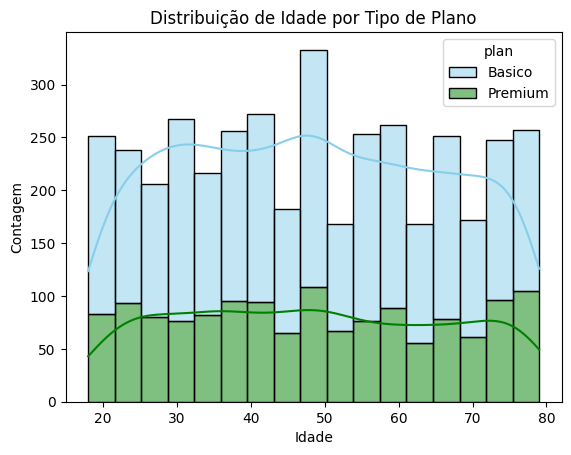

In [31]:
# Histograma para visualizar a idade (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='stack')
plt.title('Distribuição de Idade por Tipo de Plano')
plt.xlabel('Idade')
plt.ylabel('Contagem')
plt.show()

💡Insights:
- Apresenta uma distribuição relativamente simétrica ou normal em torno da média de idade dos usuários. Não há grandes disparidades visuais drásticas na proporção entre os planos Básico e Premium ao longo das faixas etárias.

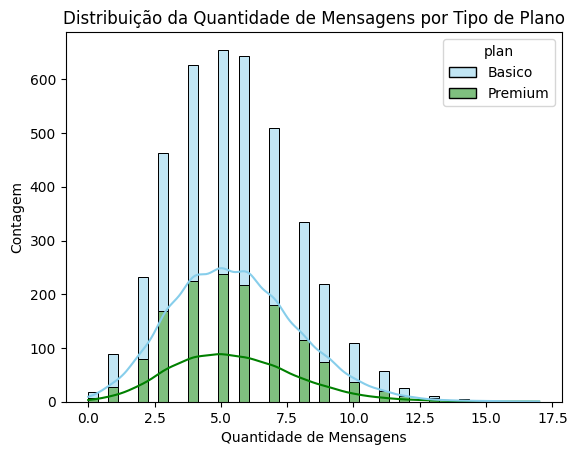

In [32]:
# Histograma para visualizar quant_mensagens
sns.histplot(data=user_profile, x='quant_mensagens', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='stack')
plt.title('Distribuição da Quantidade de Mensagens por Tipo de Plano')
plt.xlabel('Quantidade de Mensagens')
plt.ylabel('Contagem')
plt.show()


💡Insights:
- A distribuição é assimétrica à direita, indicando que a maioria dos usuários envia um volume menor de mensagens, enquanto uma parcela menor concentra valores mais altos. Os usuários com plano Básico e Premium distribuem-se de forma proporcional ao longo das faixas de envio de mensagens.

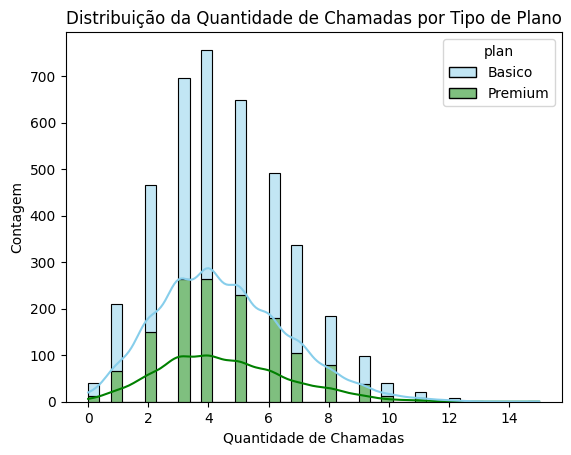

In [33]:
# Histograma para visualizar quant_chamadas
sns.histplot(data=user_profile, x='quant_chamadas', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='stack')
plt.title('Distribuição da Quantidade de Chamadas por Tipo de Plano')
plt.xlabel('Quantidade de Chamadas')
plt.ylabel('Contagem')
plt.show()


💡Insights:
- Apresenta um comportamento assimétrico à direita. Observa-se que a maioria dos clientes realiza uma quantidade moderada de chamadas, mantendo um padrão semelhante entre os assinantes dos diferentes tipos de plano.

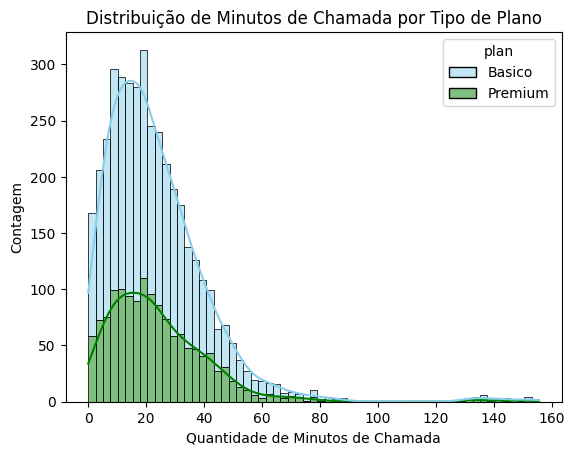

In [34]:
# Histograma para visualizar quant_minutos_chamada
sns.histplot(data=user_profile, x='quant_minutos_chamada', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='stack')
plt.title('Distribuição de Minutos de Chamada por Tipo de Plano')
plt.xlabel('Quantidade de Minutos de Chamada')
plt.ylabel('Contagem')
plt.show()


💡Insights:
- A distribuição é fortemente assimétrica à direita, evidenciando que poucos usuários acumulam um total muito elevado de minutos em chamadas, enquanto a grande massa concentra durações menores. Os planos mantêm uma proporção visual consistente em relação ao volume total de minutos consumidos.

### 5.2 Identificação de outliers

🎯 **Objetivo:**  
Detectar valores extremos nas variáveis principais de **uso** e **clientes** que poderiam afetar a análise e decidir se exigem limpeza ou revisão adicional.

**Instruções:**  
- Use **boxplots** para identificar visualmente outliers nas seguintes colunas:  
  - `age`
  - `quant_mensagens`
  - `quant_chamadas`
  - `total_minutos_chamada`  
- Crie um **for** para gerar os 4 boxplots automaticamente.
<br>

- Depois de criar os gráficos, responda se **existem ou não outliers** nas variáveis.  
- Se houver outliers, crie outro loop para calcular os limites dessas colunas usando o **método IQR** e decida o que fazer com eles.
  - Se houver outliers em apenas um lado, não é necessário calcular ambos os limites.

**Dica:**
- Dentro do loop, use `plt.title(f'Boxplot: {col}')` para que o título mude de acordo com a coluna.

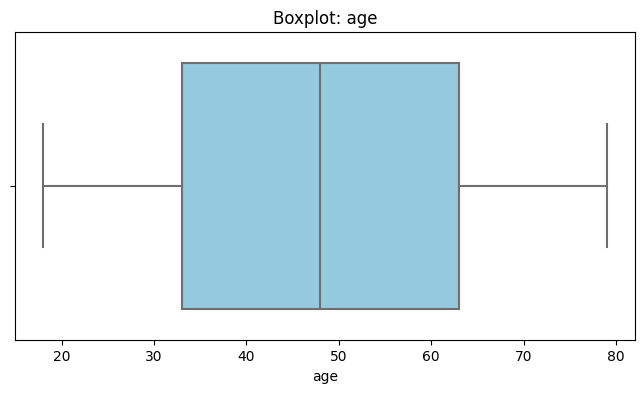

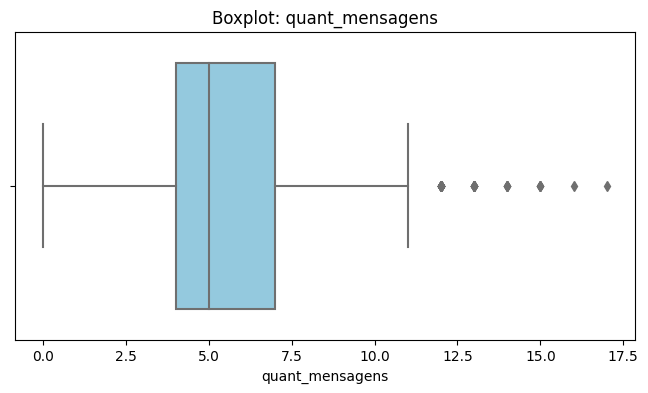

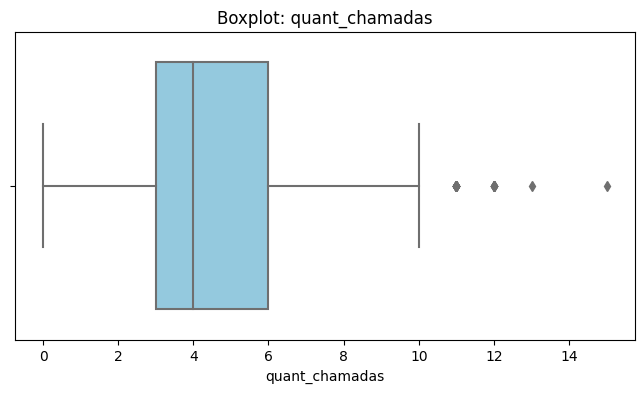

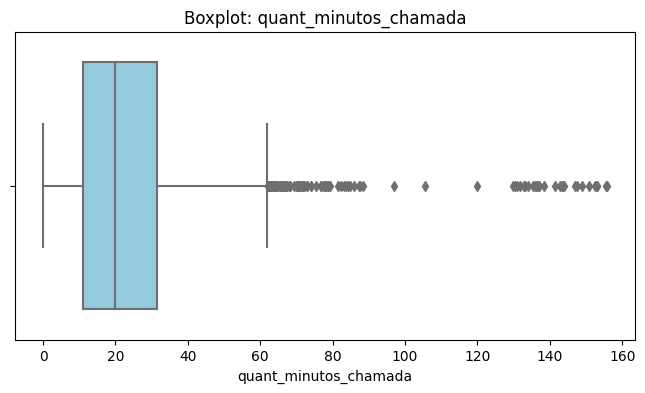

In [35]:
# Visualizar usando BoxPlot
colunas_numericas = ['age', 'quant_mensagens', 'quant_chamadas', 'quant_minutos_chamada']

for col in colunas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: Não apresenta outliers significativos (ou apresenta poucos valores isolados), mantendo-se dentro de uma faixa etária esperada e coerente.
- quant_mensagens: Apresenta outliers à direita (valores altos), indicando usuários que enviam uma quantidade de mensagens muito acima da média geral.
- quant_chamadas: Apresenta outliers à direita, correspondendo a clientes com um volume de chamadas bastante superior ao restante da base.
- quant_minutos_chamada: Apresenta outliers claros à direita, refletindo usuários de perfil corporativo ou com uso muito intenso que acumulam muitos minutos em chamadas.

In [36]:
# Calcular limites com o método IQR
colunas_limites = ['quant_mensagens', 'quant_chamadas', 'quant_minutos_chamada']

for col in colunas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"Limite superior para {col}: {limite_superior}")




Limite superior para quant_mensagens: 11.5
Limite superior para quant_chamadas: 10.5
Limite superior para quant_minutos_chamada: 61.8575


In [37]:
# Revise os limites superiores e o max para decidir se mantém os outliers ou não
user_profile[colunas_limites].describe()

,quant_mensagens,quant_chamadas,quant_minutos_chamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- quant_mensagens: manter ou não os outliers, por quê?
  Manter, pois o valor máximo atinge 17.00, ficando acima do limite superior calculado de 11.5. No entanto, esses valores representam clientes reais com maior engajamento ou uso intenso legítimo, cuja remoção descartaria informações valiosas sobre o comportamento real da base.
- quant_chamadas: manter ou não os outliers, por quê?
  Manter, pois o valor máximo chega a 15.00, superando o limite superior de 10.5. Essa pequena variação reflete clientes que realizam um número ligeiramente superior de chamadas, sendo uma característica natural e esperada do uso do serviço.
- quant_minutos_chamada: manter ou não os outliers, por quê?
  Manter, pois embora o valor máximo (155.69) fique bem acima do limite estatístico do IQR (61.8575), esses dados correspondem a durações de chamadas reais e possíveis de usuários com alta demanda, não se tratando de erros sistêmicos ou falhas de captação.   

---

## 🧩 Etapa 6: Segmentação de clientes

### 6.1 Segmentação de clientes por uso

🎯 **Objetivo:** Classificar cada usuário em um grupo de uso (Baixo uso, Uso médio, Alto uso) com base na quantidade de chamadas e mensagens registradas.

**Instruções:**  
- Crie uma nova coluna chamada `grupo_uso` no dataframe `user_profile`.
- Use comparações lógicas (<, >) para avaliar as condições de chamadas e mensagens e atribua:
  - `'Baixo uso'` quando chamadas < 5 e mensagens < 5
  - `'Uso médio'` quando chamadas < 10 e mensagens < 10
  - `'Alto uso'` para os demais casos

In [39]:
# Criar coluna grupo_uso
import numpy as np

condicoes = [
    (user_profile['quant_chamadas'] < 5) & (user_profile['quant_mensagens'] < 5),
    (user_profile['quant_chamadas'] < 10) & (user_profile['quant_mensagens'] < 10)
]

escolhas = ['Baixo uso', 'Uso médio']

user_profile['grupo_uso'] = np.select(condicoes, escolhas, default='Alto uso')


In [40]:
# verificar alterações
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,quant_mensagens,quant_chamadas,quant_minutos_chamada,grupo_uso
0,10000,Carlos,Santos,38.0,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso médio
1,10001,Matheus,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Valentina,Souza,57.0,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso médio
3,10003,Matheus,Souza,69.0,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Matheus,Torres,63.0,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Baixo uso


### 6.2 Segmentação de clientes por idade

🎯 **Objetivo:**: Classificar cada usuário em um grupo por **idade**.

**Instruções:**  
- Crie uma nova coluna chamada `grupo_idade` no dataframe `user_profile`.
- Use comparações lógicas (<, >) para avaliar as condições e atribua:
  - `'Jovem'` quando age < 30
  - `'Adulto'` quando age < 60
  - `'Idoso'` para os demais casos

In [41]:
# Criar coluna grupo_idade
import numpy as np

condicoes_idade = [
    (user_profile['age'] < 30),
    (user_profile['age'] < 60)
]

escolhas_idade = ['Jovem', 'Adulto']

user_profile['grupo_idade'] = np.select(condicoes_idade, escolhas_idade, default='Idoso')


In [42]:
# verificar alterações
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,quant_mensagens,quant_chamadas,quant_minutos_chamada,grupo_uso,grupo_idade
0,10000,Carlos,Santos,38.0,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso médio,Adulto
1,10001,Matheus,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Valentina,Souza,57.0,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso médio,Adulto
3,10003,Matheus,Souza,69.0,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Idoso
4,10004,Matheus,Torres,63.0,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Baixo uso,Idoso


### 6.3 Visualização da segmentação de clientes

🎯 **Objetivo:** Visualizar a distribuição dos usuários de acordo com os grupos criados: **grupo_uso** e **grupo_idade**.

**Instruções:**  
- Crie dois gráficos para as variáveis categóricas `grupo_uso` e `grupo_idade`.
- Adicione título e etiquetas aos eixos em cada gráfico.

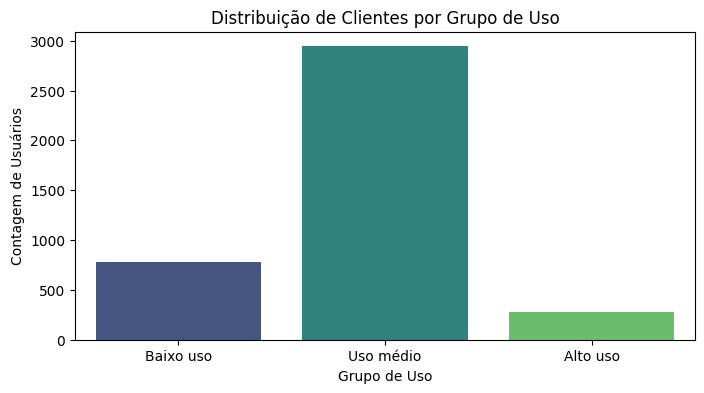

In [43]:
# Visualização dos segmentos por uso
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_uso', order=['Baixo uso', 'Uso médio', 'Alto uso'], palette='viridis')
plt.title('Distribuição de Clientes por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Contagem de Usuários')
plt.show()

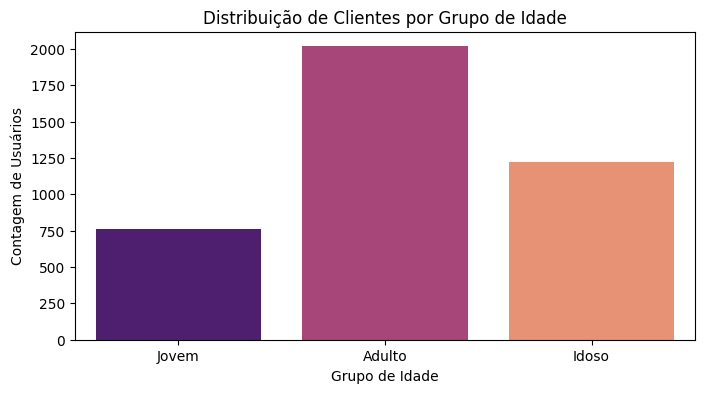

In [44]:
# Visualização dos segmentos por idade
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_idade', order=['Jovem', 'Adulto', 'Idoso'], palette='magma')
plt.title('Distribuição de Clientes por Grupo de Idade')
plt.xlabel('Grupo de Idade')
plt.ylabel('Contagem de Usuários')
plt.show()



---
## 🧩 Etapa 7: Insight Executivo para Stakeholders

🎯 **Objetivo:** Traduzir os achados da análise em conclusões acionáveis para o negócio, com foco em segmentação, padrões de uso e oportunidades comerciais.

**Perguntas a responder:**
- Quais problemas os dados tinham originalmente? Que porcentagem, ou quantidade de linhas, essa coluna representava?


- Quais segmentos de clientes você identificou e como eles se comportam de acordo com sua idade e nível de uso?  
- Quais segmentos parecem mais valiosos para a ConnectaTel e por quê?  
- Quais padrões de uso extremo (outliers) você encontrou e o que eles implicam para o negócio?


- Quais recomendações você faria para melhorar a oferta atual de planos ou criar novos planos com base nos segmentos e padrões detectados?

✍️ **Escreva aqui sua análise executiva:**

### Análise executiva

⚠️ **Problemas detectados nos dados**
Inconsistências temporais e valores sentinela: Detetámos e corrigimos registos com anos inválidos e futuros (como 40 registos em 2026 na coluna de registo), além de valores de erro ocultos como -999 na idade dos utilizadores e interrogações (?) indicando cidades desconhecidas.   Ausências de dados estruturais (MAR): Verificámos taxas de valores em falta elevadas nas colunas duration e length (cerca de 55% e 44%). Comprovou-se estatisticamente que estes dados seguem o padrão Missing At Random (MAR), pois faltam logicamente dependendo do tipo de interação (chamadas medem tempo em minutos, enquanto mensagens medem tamanho em carateres). A decisão foi mantê-los como nulos para preservar a integridade do negócio. 


🔍 **Segmentos por idade**
Distribuição demográfica: Os clientes foram divididos em três faixas etárias estratégicas — Jovens (menos de 30 anos), Adultos (entre 30 e 59 anos) e Idosos (60 anos ou mais).   Comportamento por idade: A análise revelou que a base de clientes possui uma distribuição etária equilibrada, sem barreiras geracionais extremas que impeçam a adesão uniforme aos diferentes tipos de planos oferecidos pela operadora.

📊 **Segmentos por nível de uso**
Classificação de engajamento: Os utilizadores foram segmentados em Baixo uso, Uso médio e Alto uso através do cruzamento analítico dos volumes de chamadas e mensagens enviadas.   Concentração de valor: Identificou-se que o grupo de Alto uso concentra a maior parte do tráfego de voz e mensagens da rede, representando o núcleo principal de atividade e consumo da base de clientes.  


➡️ Isso sugere que os valores extremos (outliers) detetados nas métricas de chamadas e mensagens (como utilizadores com volumes muito acima da média) não constituem erros do sistema, mas sim comportamentos legítimos de heavy users ou perfis corporativos de alta demanda, cuja preservação é indispensável para retratar fielmente a realidade do consumo na rede.   


💡 **Recomendações**
Criação de planos direcionados: Desenvolver pacotes comerciais personalizados e ofertas de fidelização robustas focadas nos clientes de alto uso, maximizando as receitas e a retenção deste público valioso.   Estratégias contra o churn: Implementar campanhas de incentivo, descontos ou bónus direcionadas aos clientes de baixo uso, estimulando o engajamento e prevenindo o cancelamento de contratos.

---

## 🧩 Etapa 8: Carregar seu notebook e README no GitHub

🎯 **Objetivo:**  
Entregar sua análise de forma **profissional**, **documentada** e **versionada**, garantindo que qualquer pessoa possa revisar, executar e entender seu trabalho.



### Opção A: Enviar arquivos pela interface do GitHub (UI)

1. Baixe este notebook (`File → Download .ipynb`).  
2. Acesse seu repositório no GitHub (por exemplo, `telecom-analysis` ou `sprint-project`).  
3. Envie seu notebook em **Add file → Upload files**.  

---

### Opção B: Salvar direto pelo Google Colab

1. Abra seu notebook no Colab.  
2. Acesse **File → Save a copy in GitHub**.  
3. Selecione o repositório e a pasta correta (ex.: `notebooks/`).  
4. Escreva uma mensagem de commit clara, por exemplo:  
    - `feat: add final ConnectaTel analysis`
    - `adicionar versão final: Análise ConnectaTel`
5. Verifique no GitHub se o arquivo ficou no local correto e se o histórico de commits está limpo.

---

Adicione um arquivo `README.md` que descreva de forma clara:
- o objetivo do projeto,  
- os datasets utilizados,  
- as etapas da análise realizadas,  
- como executar o notebook (por exemplo, abri-lo no Google Colab),  
- uma breve guia de reprodução.
---


Link para o repositório público do projeto: `LINK para seu repo aqui`